## Phase 2: Fine-Tuning with Full Model

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import os
import shutil
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
import sys
import numpy as np
from tqdm.auto import tqdm
import torch.nn.functional as F

from torchcam.methods import GradCAM
import random
from PIL import Image

if not hasattr(torch, "_six"):
    from unittest.mock import MagicMock
    mock = MagicMock()
    mock.string_classes = (str, bytes)
    torch._six = mock
    sys.modules["torch._six"] = mock

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load the model from the checkpoint
model = torch.hub.load('pytorch/vision:v0.10.0', 'mobilenet_v2', pretrained=True)
model.classifier[1] = nn.Linear(model.last_channel, 4)
model = model.to(device)

# Load the saved weights from phase 1
checkpoint_path = "../4_models/agroStake-0.1-p2-finetuned.pth"
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
print(f"Model loaded from {checkpoint_path}")

Using cache found in C:\Users\xared/.cache\torch\hub\pytorch_vision_v0.10.0
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\xared\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model loaded from ../4_models/agroStake-0.1-p2-finetuned.pth


C:\Users\xared\AppData\Local\Temp\ipykernel_26248\3676526158.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(checkpoint_path, map_locat

In [3]:
# convert to h5 format
h5_path = "../4_models/agroStake-0.1-alpha.h5"
torch.save(model.state_dict(), h5_path)

In [5]:
# Find the weights of the model
weights = model.state_dict()
print("Model weights:")
for name, param in weights.items():
    print(f"{name}: {param.shape}")

Model weights:
features.0.0.weight: torch.Size([32, 3, 3, 3])
features.0.1.weight: torch.Size([32])
features.0.1.bias: torch.Size([32])
features.0.1.running_mean: torch.Size([32])
features.0.1.running_var: torch.Size([32])
features.0.1.num_batches_tracked: torch.Size([])
features.1.conv.0.0.weight: torch.Size([32, 1, 3, 3])
features.1.conv.0.1.weight: torch.Size([32])
features.1.conv.0.1.bias: torch.Size([32])
features.1.conv.0.1.running_mean: torch.Size([32])
features.1.conv.0.1.running_var: torch.Size([32])
features.1.conv.0.1.num_batches_tracked: torch.Size([])
features.1.conv.1.weight: torch.Size([16, 32, 1, 1])
features.1.conv.2.weight: torch.Size([16])
features.1.conv.2.bias: torch.Size([16])
features.1.conv.2.running_mean: torch.Size([16])
features.1.conv.2.running_var: torch.Size([16])
features.1.conv.2.num_batches_tracked: torch.Size([])
features.2.conv.0.0.weight: torch.Size([96, 16, 1, 1])
features.2.conv.0.1.weight: torch.Size([96])
features.2.conv.0.1.bias: torch.Size([96]

In [3]:
# Data paths and setup
grapeHealthy = "../0_data/0_Raw/plantvillage-dataset/plantvillage dataset/color/Grape___healthy/"
grapeLeafBlight = "../0_data/0_Raw/plantvillage-dataset/plantvillage dataset/color/Grape___Leaf_blight_(Isariopsis_Leaf_Spot)/"
grapeEsca = "../0_data/0_Raw/plantvillage-dataset/plantvillage dataset/color/Grape___Esca_(Black_Measles)/"
grapeBlackRot = "../0_data/0_Raw/plantvillage-dataset/plantvillage dataset/color/Grape___Black_rot/"

proccessedRoot = "../0_data/1_Proccessed/plantvillage-dataset/"

# Load datasets and dataloaders
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(root=os.path.join(proccessedRoot, "train"), transform=transform)
test_dataset = datasets.ImageFolder(root=os.path.join(proccessedRoot, "test"), transform=transform)
val_dataset = datasets.ImageFolder(root=os.path.join(proccessedRoot, "validate"), transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print(f"Classes: {train_dataset.classes}")

Classes: ['black_rot', 'esca', 'healthy', 'leaf_blight']


In [4]:
from sklearn.metrics import recall_score

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    pbar = tqdm(dataloader, desc="Training", leave=False)
    for i, (inputs, labels) in enumerate(dataloader):
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        if (i + 1) % 10 == 0:
            pbar.update(10)
            pbar.set_postfix({"Loss": f"{loss.item():.4f}"})
            pbar.set_postfix_str(f"recall score: {recall_score(all_labels, all_preds, average='macro'):.4f}")            
    
    epoch_loss = running_loss / len(dataloader.dataset)
    return epoch_loss, all_preds, all_labels

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    pbar = tqdm(dataloader, desc="Evaluating", leave=False)
    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloader):
            inputs, labels = inputs.to(device), labels.to(device)
            
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            if (i + 1) % 10 == 0:
                pbar.update(10)
                pbar.set_postfix({"Loss": f"{loss.item():.4f}"})
                pbar.set_postfix_str(f"recall score: {recall_score(all_labels, all_preds, average='macro'):.4f}")
                                
    epoch_loss = running_loss / len(dataloader.dataset)
    recall = recall_score(all_labels, all_preds, average='macro')
    return epoch_loss, recall

In [5]:
# Phase 2: Unfreeze backbone and fine-tune entire model
# 1. Unfreeze all parameters
for param in model.parameters():
    param.requires_grad = True

# 2. Setup loss and optimizer for phase 2
class_counts = [826, 968, 296, 753]
total_samples = sum(class_counts)
num_classes = len(class_counts)
weights = [total_samples / (num_classes * count) for count in class_counts]
class_weights = torch.tensor(weights, dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

# 3. Lower learning rate significantly for fine-tuning
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

best_recall = 0.0
print("Phase 2 Setup Complete: Backbone UNFROZEN with lr=1e-5")

Phase 2 Setup Complete: Backbone UNFROZEN with lr=1e-5


In [6]:
# Phase 2: Fine-tuning loop
num_epochs_p2 = 5

for epoch in range(num_epochs_p2):
    train_loss, _, _ = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_recall = evaluate(model, val_loader, criterion, device)
    
    print(f"Phase 2 - Epoch {epoch+1}/{num_epochs_p2} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Recall: {val_recall:.4f}")
    
    # Save best model
    if val_recall > best_recall:
        best_recall = val_recall
        torch.save(model.state_dict(), "../4_models/agroStake-0.1-p2-finetuned.pth")
        print(f"Best model updated with recall: {best_recall:.4f}")
    
    scheduler.step()

print(f"\nPhase 2 Complete! Best Recall: {best_recall:.4f}")

Training:   0%|          | 0/89 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/13 [00:00<?, ?it/s]

Phase 2 - Epoch 1/5 | Train Loss: 0.0301 | Val Loss: 0.0134 | Val Recall: 1.0000
Best model updated with recall: 1.0000


Training:   0%|          | 0/89 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/13 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/13 [00:00<?, ?it/s]

Phase 2 - Epoch 4/5 | Train Loss: 0.0070 | Val Loss: 0.0097 | Val Recall: 0.9982


Training:   0%|          | 0/89 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/13 [00:00<?, ?it/s]

Phase 2 - Epoch 5/5 | Train Loss: 0.0054 | Val Loss: 0.0042 | Val Recall: 1.0000

Phase 2 Complete! Best Recall: 1.0000


In [7]:
val_preds = []
val_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        val_preds.extend(preds.cpu().numpy())
        val_labels.extend(labels.cpu().numpy())

print("Data captured for Confusion Matrix.")


Data captured for Confusion Matrix.


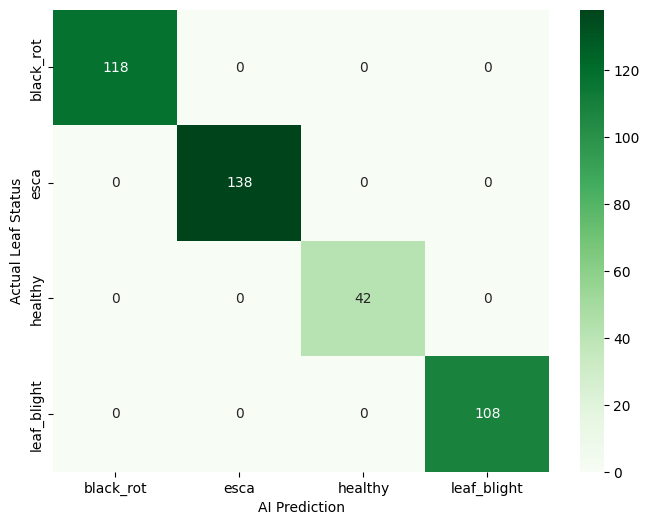

              precision    recall  f1-score   support

   black_rot       1.00      1.00      1.00       118
        esca       1.00      1.00      1.00       138
     healthy       1.00      1.00      1.00        42
 leaf_blight       1.00      1.00      1.00       108

    accuracy                           1.00       406
   macro avg       1.00      1.00      1.00       406
weighted avg       1.00      1.00      1.00       406



In [8]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# The Matrix
cm = confusion_matrix(val_labels, val_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=train_dataset.classes, 
            yticklabels=train_dataset.classes)
plt.ylabel('Actual Leaf Status')
plt.xlabel('AI Prediction')
plt.show()

# The Text Report (This is the one that proves your 99.46% Recall)
print(classification_report(val_labels, val_preds, target_names=train_dataset.classes))

Inference in progress...

--- Phase 2 Final Classification Report ---
              precision    recall  f1-score   support

   black_rot       1.00      1.00      1.00       118
        esca       1.00      1.00      1.00       138
     healthy       1.00      1.00      1.00        42
 leaf_blight       1.00      1.00      1.00       108

    accuracy                           1.00       406
   macro avg       1.00      1.00      1.00       406
weighted avg       1.00      1.00      1.00       406



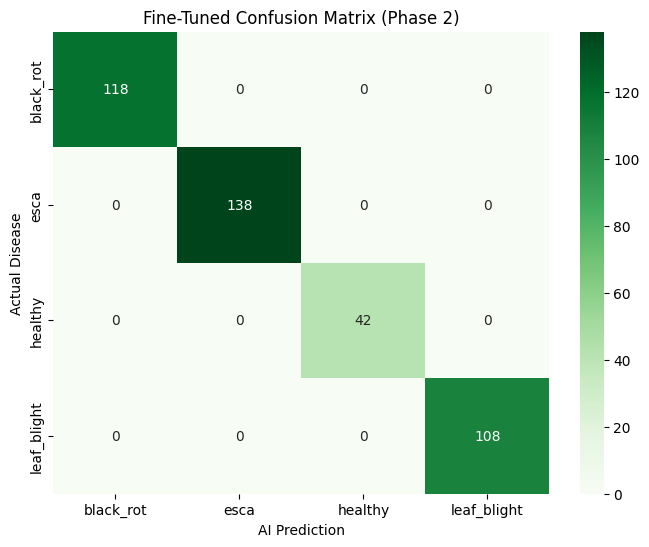

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def final_audit(model, dataloader, device, class_names):
    model.eval()
    all_preds = []
    all_labels = []
    
    print("Inference in progress...")
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # 1. Text Report
    print("\n--- Phase 2 Final Classification Report ---")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    # 2. Confusion Matrix Heatmap
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8, 6), dpi=100)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
                xticklabels=class_names, yticklabels=class_names)
    plt.title("Fine-Tuned Confusion Matrix (Phase 2)")
    plt.ylabel("Actual Disease")
    plt.xlabel("AI Prediction")
    plt.show()

# Run the audit
final_audit(model, val_loader, device, train_dataset.classes)

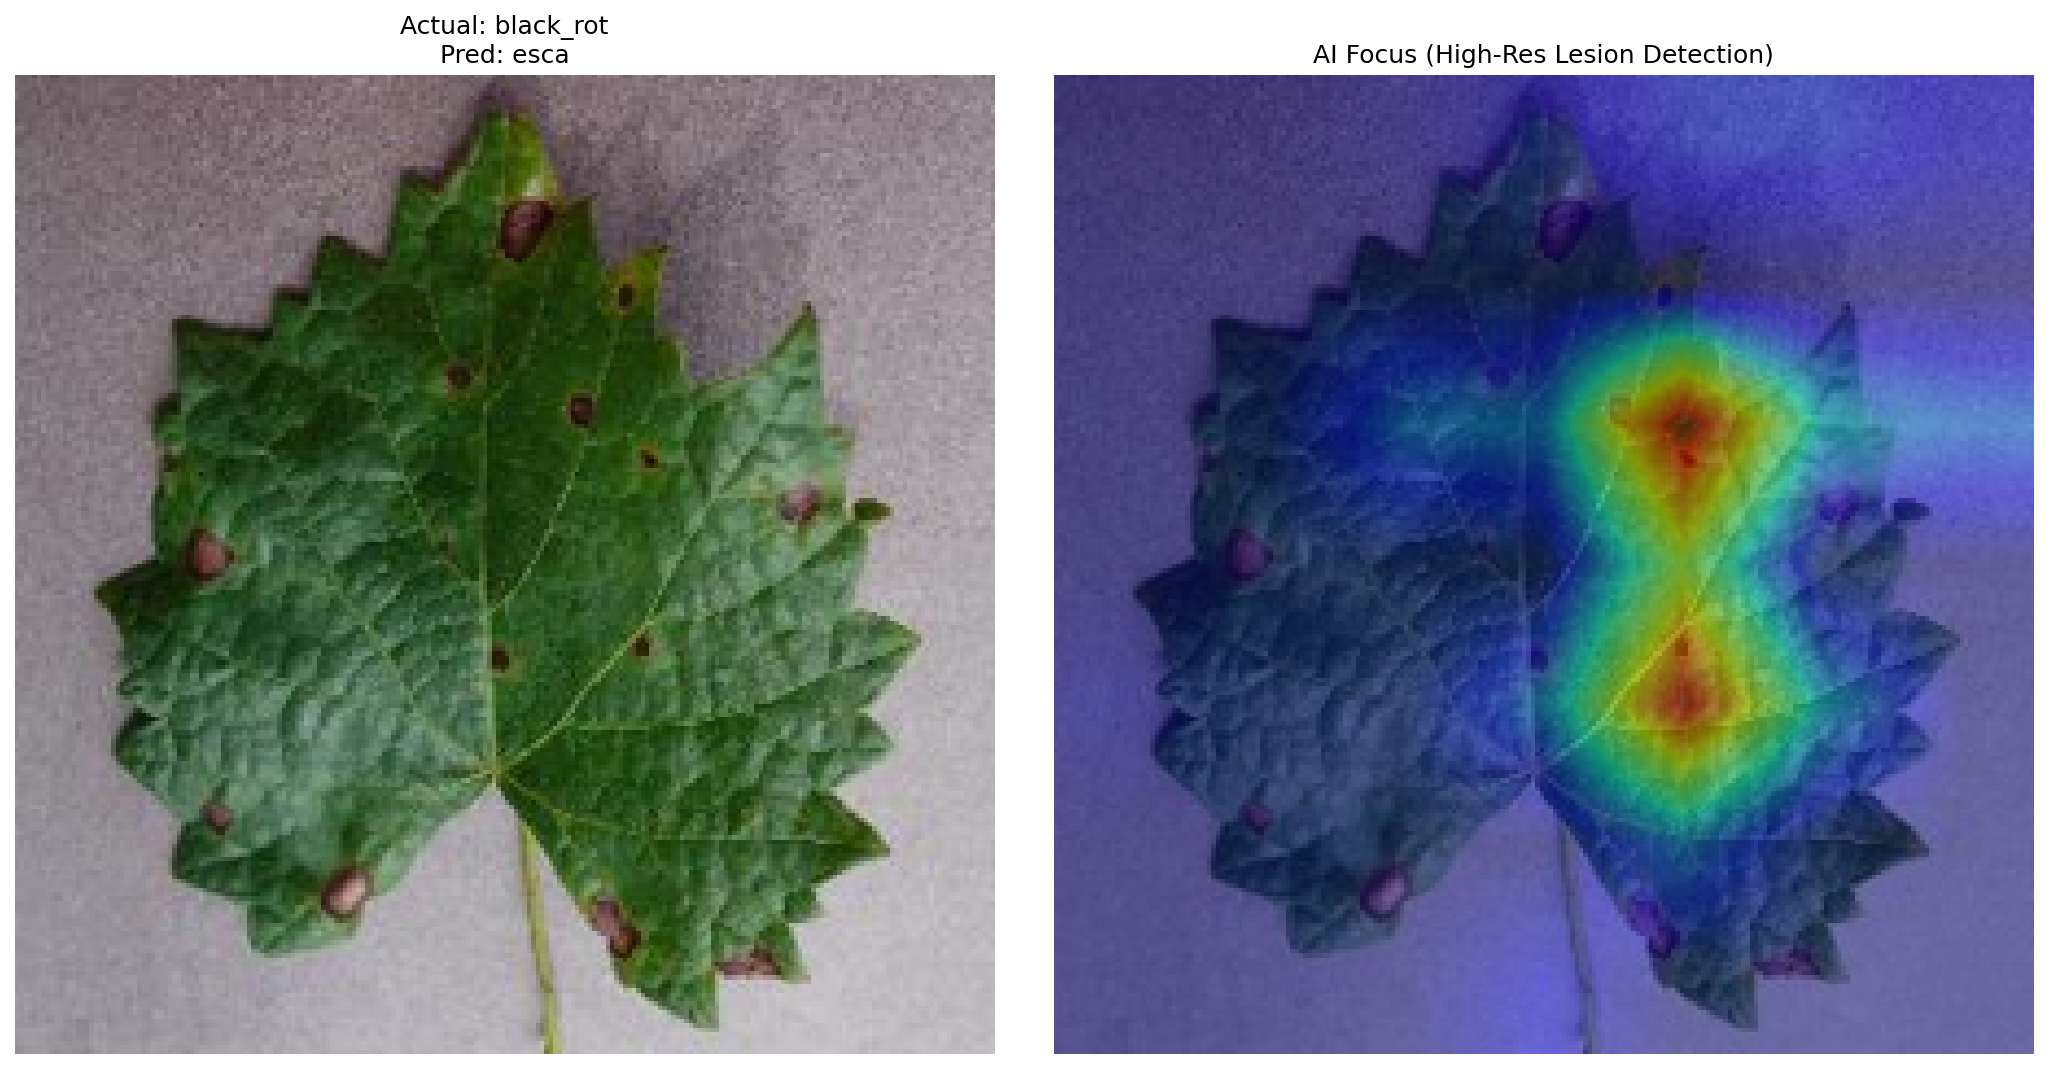

In [16]:
def visualize_model_focus_high_res(model, dataset, device):
    model.train() 
    cam_extractor = GradCAM(model, target_layer='features')

    # 1. Grab random sample
    idx = random.randint(0, len(dataset) - 1)
    img_path, label = dataset.samples[idx]
    img_tensor, _ = dataset[idx]
    
    # 2. Prepare Input
    input_tensor = img_tensor.unsqueeze(0).to(device)
    input_tensor.requires_grad_(True) 
    for param in model.features.parameters():
        param.requires_grad = True

    # 3. Forward pass
    out = model(input_tensor)
    pred_idx = out.squeeze(0).argmax().item()
    activation_map = cam_extractor(pred_idx, out)
    
    # 4. Clean up hooks and Re-freeze
    cam_extractor.remove_hooks()
    for param in model.features.parameters():
        param.requires_grad = False
    model.eval()

    # 5. HIGH-RES INTERPOLATION
    # Convert activation map to tensor for interpolation
    raw_heatmap = activation_map[0].squeeze(0).unsqueeze(0).unsqueeze(0) 
    
    # Scale up the 7x7 heatmap to 224x224 using Bilinear Interpolation
    hi_res_heatmap = F.interpolate(raw_heatmap, size=(224, 224), mode='bilinear', align_corners=False)
    hi_res_heatmap = hi_res_heatmap.squeeze().cpu().numpy()

    # 6. Normalize
    hi_res_heatmap = (hi_res_heatmap - hi_res_heatmap.min()) / (hi_res_heatmap.max() - hi_res_heatmap.min() + 1e-8)

    # 7. Plotting with High DPI
    raw_img = Image.open(img_path).convert('RGB').resize((224, 224))
    
    plt.figure(figsize=(14, 7), dpi=150) # Higher DPI for better resolution
    
    plt.subplot(1, 2, 1)
    plt.imshow(raw_img)
    plt.title(f"Actual: {dataset.classes[label]}\nPred: {dataset.classes[pred_idx]}", fontsize=12)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(raw_img)
    # Using 'jet' with a smooth interpolation for the 'glow' effect
    plt.imshow(hi_res_heatmap, cmap='jet', alpha=0.45, interpolation='bilinear') 
    plt.title("AI Focus (High-Res Lesion Detection)", fontsize=12)
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

# Run the high-res version:
visualize_model_focus_high_res(model, val_dataset, device)